### Exploratory Data Analysis of Pregnancy Cohort ###

Phenotyped from DeSynpuf data using N3C Pregnancy phenotyping algorithm. 

## Confusions/Questions ##

- difference between DELIV and LB outcomes? DELIV made me feel like that was normal but it includes a lot of maternal complications during delivery like pre-eclampsia is in there

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
final_cohort = pd.read_csv('../pheno_data/step7_pregnancy_cohort_final.csv')
final_cohort.head()

,person_id,episode_number,inferred_episode_start,inferred_episode_end,recorded_episode_start,recorded_episode_end,final_outcome_category,gestational_age_days,HIP_flag,PPS_flag,precision_category,year_of_birth,date_of_birth,age_at_episode_start,race,ethnicity,race_ethnicity,preterm_status,location_id
0,9,1,2008-11-29,2009-09-26,2008-11-29,2009-09-26,DELIV,301,1,0,month,1976,1976-09-01,32.243669,White,Not Hispanic or Latino,White Non-Hispanic,0,9
1,292,1,2007-10-24,2008-08-20,2007-10-24,2008-08-20,DELIV,301,1,0,month,1981,1981-03-01,26.647502,White,Not Hispanic or Latino,White Non-Hispanic,0,215
2,302,1,2007-12-08,2008-10-04,2007-12-08,2008-10-04,DELIV,301,1,0,month,1969,1969-10-01,38.184805,White,Not Hispanic or Latino,White Non-Hispanic,0,214
3,515,1,2007-04-24,2008-02-19,2007-04-24,2008-02-19,DELIV,301,1,0,month,1979,1979-04-01,28.062971,White,Not Hispanic or Latino,White Non-Hispanic,0,347
4,784,1,2007-07-30,2008-05-26,2007-07-30,2008-05-26,DELIV,301,1,0,month,1979,1979-09-01,27.909651,White,Not Hispanic or Latino,White Non-Hispanic,0,60


Distributions of Race, Location, Pregnancy Outcomes, and Pregnancy Timelines

In [3]:
print("Value Counts for Pregnancy Outcomes and Preterm Status:")
print(final_cohort['final_outcome_category'].value_counts())
print(final_cohort['preterm_status'].value_counts())
# print(final_cohort['final_outcome_category'].value_counts(normalize=True))

Value Counts for Pregnancy Outcomes and Preterm Status:
final_outcome_category
DELIV    17733
LB         295
AB         104
PREG       102
SA          60
SB          55
ECT         17
Name: count, dtype: int64
preterm_status
0    18187
1      179
Name: count, dtype: int64


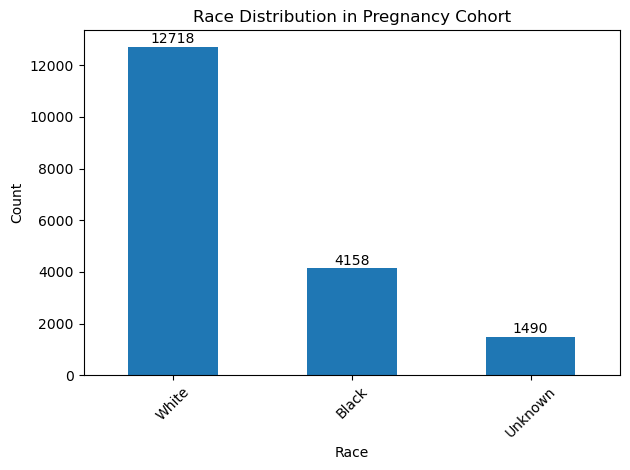

In [4]:
# make bar chart of race distribution in the cohort with counts above bars
ax = final_cohort['race'].value_counts().plot(kind='bar')
plt.title('Race Distribution in Pregnancy Cohort')
plt.xlabel('Race') 
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
for i, v in enumerate(final_cohort['race'].value_counts()):
    ax.text(i, v + 10, str(v), ha='center', va='bottom')
plt.show()


In [17]:
# make table one with demographic and clinical characteristics of the cohort, stratified by race and delivery outcome
# use table one package in python
from tableone import TableOne
columns = ['race', 'final_outcome_category']
categorical = ['final_outcome_category']
table_one = TableOne(final_cohort, columns=columns, categorical=categorical, groupby='race')
print(table_one.tabulate(tablefmt="fancy_grid"))

╒═══════════════════════════════╤═══════╤═══════════╤══════════════╤═════════════╤═════════════╤══════════════╕
│                               │       │ Missing   │ Overall      │ Black       │ Unknown     │ White        │
╞═══════════════════════════════╪═══════╪═══════════╪══════════════╪═════════════╪═════════════╪══════════════╡
│ n                             │       │           │ 18366        │ 4158        │ 1490        │ 12718        │
├───────────────────────────────┼───────┼───────────┼──────────────┼─────────────┼─────────────┼──────────────┤
│ final_outcome_category, n (%) │ AB    │           │ 104 (0.6)    │ 24 (0.6)    │ 9 (0.6)     │ 71 (0.6)     │
├───────────────────────────────┼───────┼───────────┼──────────────┼─────────────┼─────────────┼──────────────┤
│                               │ DELIV │           │ 17733 (96.6) │ 3996 (96.1) │ 1434 (96.2) │ 12303 (96.7) │
├───────────────────────────────┼───────┼───────────┼──────────────┼─────────────┼─────────────┼────────

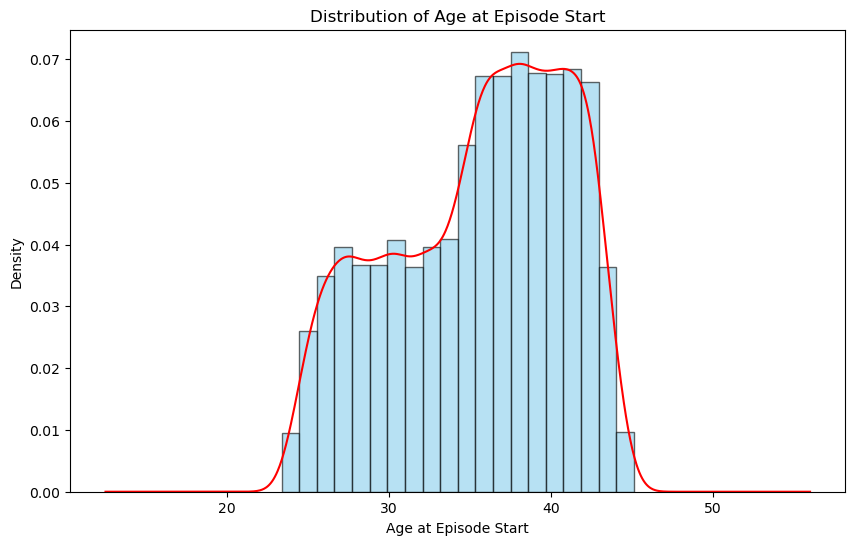

In [5]:
# make distribution of age at delivery with histogram and density plot
plt.figure(figsize=(10, 6))
plt.hist(final_cohort['age_at_episode_start'], bins=20, alpha=0.6, density=True, color='skyblue', edgecolor='black')
final_cohort['age_at_episode_start'].plot(kind='kde', color='red')
plt.title('Distribution of Age at Episode Start')
plt.xlabel('Age at Episode Start')
plt.ylabel('Density')
plt.show()

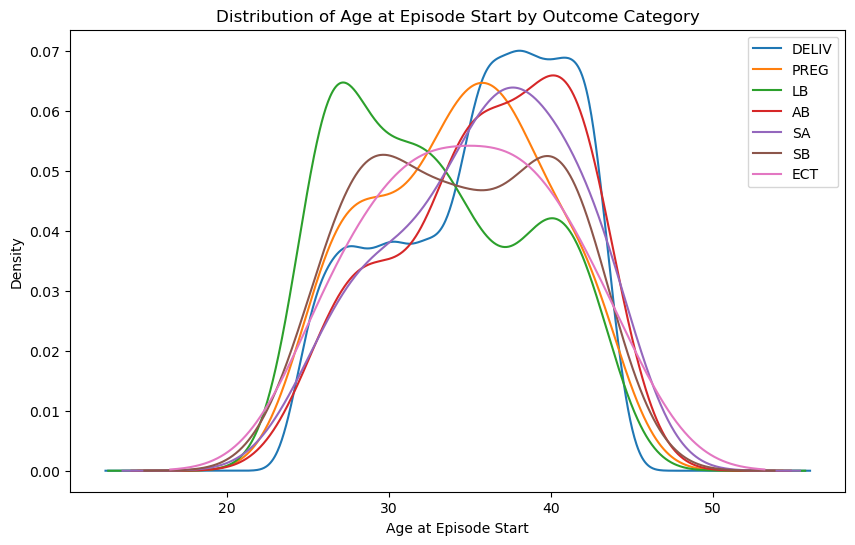

In [6]:
# distribution of age at episode start stratified by final outcome category
plt.figure(figsize=(10, 6))
for outcome in final_cohort['final_outcome_category'].unique():
    subset = final_cohort[final_cohort['final_outcome_category'] == outcome]
    subset['age_at_episode_start'].plot(kind='kde', label=outcome)
plt.title('Distribution of Age at Episode Start by Outcome Category')
plt.xlabel('Age at Episode Start')
plt.ylabel('Density')
plt.legend()
plt.show()

# # distribution of gestational_age_days stratified by final outcome category, so subplots for each outcome category
# --> this didn't work because gestational age is recorded as the same for all patients with a given outcome

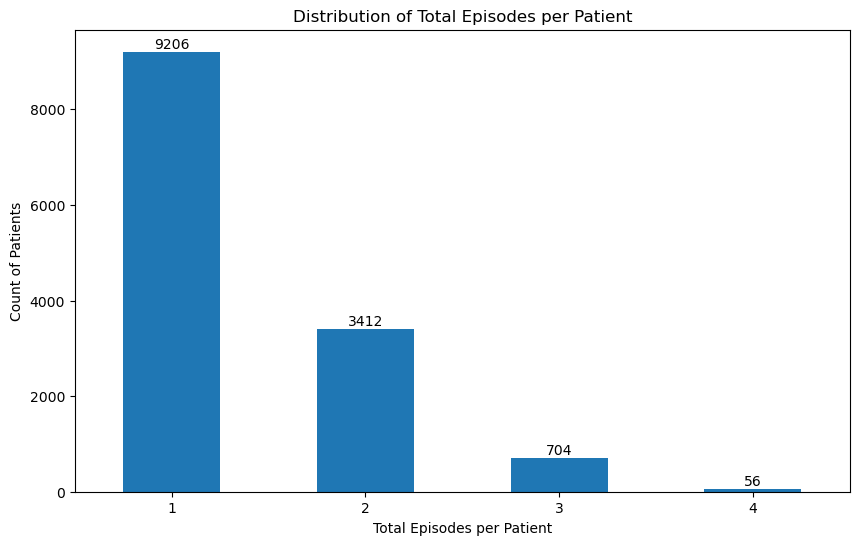

In [7]:
# distribution of total episodes per patient

episode_counts = final_cohort.groupby('person_id').size()

# label counts above bars in histogram of episode counts, and align x-axis ticks with integer episode counts
plt.figure(figsize=(10, 6))
ax = episode_counts.value_counts().sort_index().plot(kind='bar')
plt.title('Distribution of Total Episodes per Patient')
plt.xlabel('Total Episodes per Patient')
plt.ylabel('Count of Patients')
plt.xticks(rotation=0)
for i, v in enumerate(episode_counts.value_counts().sort_index()):
    ax.text(i, v + 10, str(v), ha='center', va='bottom')
plt.show()

# EDA for Longitudinal Information

how much longitudinal data do we have for each patient, stratified by birth outcome + preterm status? stratified by race? stratified by age at pregnancy start?

what kind of data do we have for each patient? how many lab measurements, how many medications, how many diagnoses? stratified by birth outcome + preterm status too would be helpful

Loading pregnancy cohort and clinical data...
Pregnancy episodes: 18,366
Unique patients: 13,378
Outcome categories: {'DELIV': 17733, 'LB': 295, 'AB': 104, 'PREG': 102, 'SA': 60, 'SB': 55, 'ECT': 17}

Clinical records:
  - Drug exposures: 1,766,129
  - Measurements: 936,197
  - Observations: 1,162,668
  - Procedures: 3,263,609

SINGLE PATIENT TIMELINE EXAMPLE
✓ Saved: single_patient_timeline.png


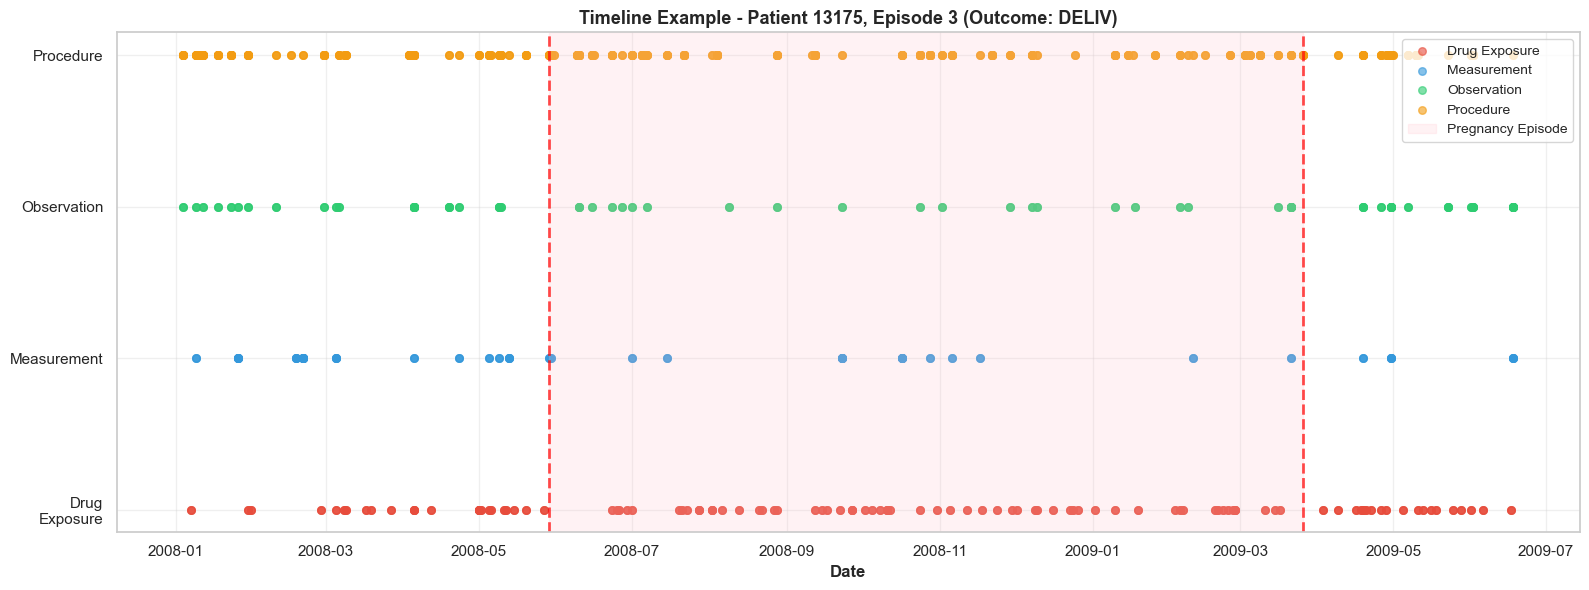


PATIENT DATA SPAN ANALYSIS
✓ Saved: patient_data_span_analysis.png


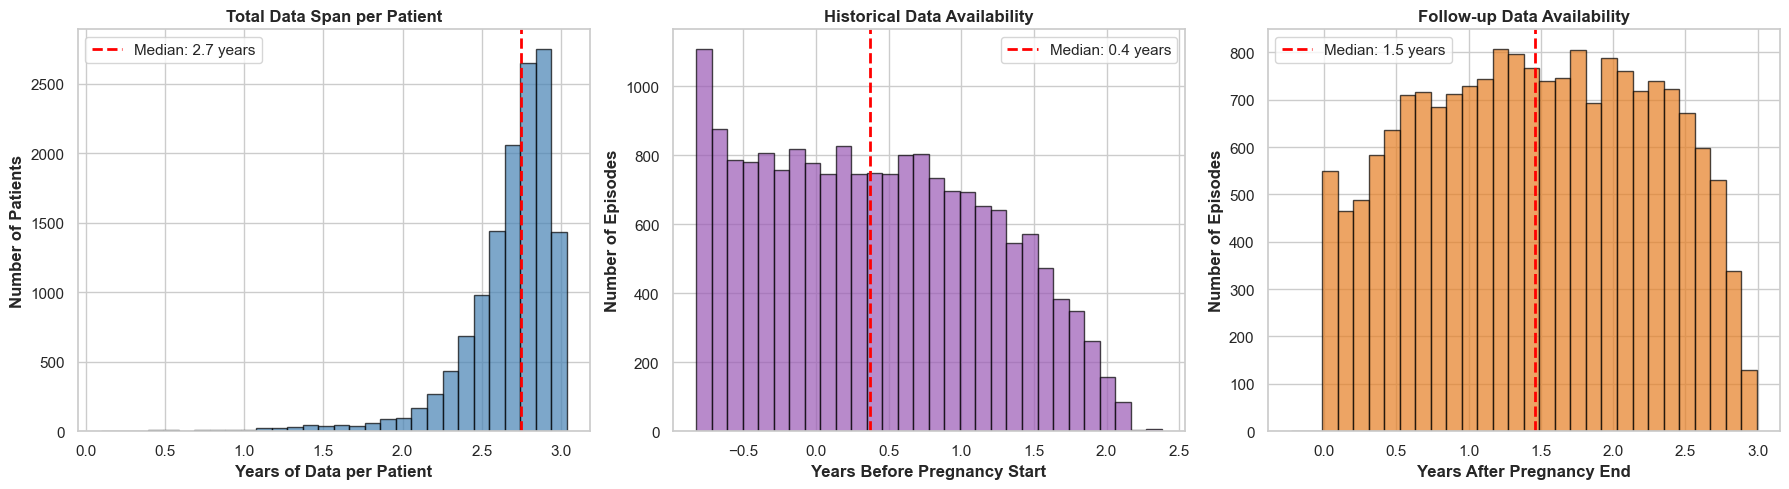


Data Span Summary:
  - Median total data span: 2.7 years
  - Median data before pregnancy: 0.4 years
  - Median data after pregnancy: 1.5 years

ANALYSIS COMPLETE


In [ ]:
"""
Data Richness Temporal Analysis for Pregnancy Cohort
====================================================

This cell analyzes temporal patterns of data richness across 4 clinical OMOP tables:
- Single patient timeline example
- Cohort-level temporal patterns stratified by outcome and data type

code in this cell is generated by Cursor
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings

warnings.filterwarnings('ignore')

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 10

colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

# LOAD DATA

print("Loading pregnancy cohort and clinical data...")

# Load pregnancy episodes
pregnancy_cohort = pd.read_csv('../pheno_data/step7_pregnancy_cohort_final.csv')
pregnancy_cohort['inferred_episode_start'] = pd.to_datetime(pregnancy_cohort['inferred_episode_start'])
pregnancy_cohort['inferred_episode_end'] = pd.to_datetime(pregnancy_cohort['inferred_episode_end'])

print(f"Pregnancy episodes: {len(pregnancy_cohort):,}")
print(f"Unique patients: {pregnancy_cohort['person_id'].nunique():,}")
print(f"Outcome categories: {pregnancy_cohort['final_outcome_category'].value_counts().to_dict()}")

# Load clinical tables
drug_exp = pd.read_csv('cohort_drug_exposure.csv')
measurements = pd.read_csv('cohort_measurements.csv')
observations = pd.read_csv('cohort_observations.csv')
procedures = pd.read_csv('cohort_procedures.csv')

# Parse dates in clinical tables
drug_exp['date'] = pd.to_datetime(drug_exp.get('drug_exposure_start_date', drug_exp.columns[0]), errors='coerce')
measurements['date'] = pd.to_datetime(measurements.get('measurement_date', measurements.columns[0]), errors='coerce')
observations['date'] = pd.to_datetime(observations.get('observation_date', observations.columns[0]), errors='coerce')
procedures['date'] = pd.to_datetime(procedures.get('procedure_date', procedures.columns[0]), errors='coerce')

print(f"\nClinical records:")
print(f"  - Drug exposures: {len(drug_exp):,}")
print(f"  - Measurements: {len(measurements):,}")
print(f"  - Observations: {len(observations):,}")
print(f"  - Procedures: {len(procedures):,}")

# SINGLE PATIENT TIMELINE EXAMPLE

print("\n" + "="*80)
print("SINGLE PATIENT TIMELINE EXAMPLE")
print("="*80)

# Find a patient with rich data across all tables
sample_patients = pregnancy_cohort['person_id'].unique()[:200]
best_patient = None
best_count = 0

for pid in sample_patients:
    preg_eps = pregnancy_cohort[pregnancy_cohort['person_id'] == pid]
    
    for _, ep in preg_eps.iterrows():
        ep_start = ep['inferred_episode_start']
        ep_end = ep['inferred_episode_end']
        
        # Count records in each table during this episode
        drug_count = len(drug_exp[(drug_exp['person_id'] == pid) & 
                                  (drug_exp['date'] >= ep_start) & 
                                  (drug_exp['date'] <= ep_end)])
        meas_count = len(measurements[(measurements['person_id'] == pid) & 
                                      (measurements['date'] >= ep_start) & 
                                      (measurements['date'] <= ep_end)])
        obs_count = len(observations[(observations['person_id'] == pid) & 
                                     (observations['date'] >= ep_start) & 
                                     (observations['date'] <= ep_end)])
        proc_count = len(procedures[(procedures['person_id'] == pid) & 
                                    (procedures['date'] >= ep_start) & 
                                    (procedures['date'] <= ep_end)])
        
        total = drug_count + meas_count + obs_count + proc_count
        
        if total > best_count and min([drug_count, meas_count, proc_count]) > 0:
            best_count = total
            best_patient = {
                'person_id': pid,
                'episode': ep['episode_number'],
                'start': ep_start,
                'end': ep_end,
                'outcome': ep['final_outcome_category']
            }

if best_patient:
    fig2 = plt.figure(figsize=(16, 6))
    ax = plt.gca()
    
    pid = best_patient['person_id']
    ep_start = best_patient['start']
    ep_end = best_patient['end']
    
    # Get all records for this patient around the episode
    window_start = ep_start - timedelta(days=180)
    window_end = ep_end + timedelta(days=90)
    
    # Plot records
    y_offset = 0
    for df, color, label in [
        (drug_exp, colors[0], 'Drug Exposure'),
        (measurements, colors[1], 'Measurement'),
        (observations, colors[2], 'Observation'),
        (procedures, colors[3], 'Procedure')
    ]:
        person_data = df[(df['person_id'] == pid) & 
                         (df['date'] >= window_start) & 
                         (df['date'] <= window_end)].copy()
        
        if not person_data.empty:
            ax.scatter(person_data['date'], 
                       [y_offset] * len(person_data),
                       alpha=0.6, s=30, color=color, label=label)
        
        y_offset += 1
    
    # Highlight pregnancy episode window
    ax.axvspan(ep_start, ep_end, alpha=0.2, color='pink', label='Pregnancy Episode')
    ax.axvline(ep_start, color='red', linestyle='--', linewidth=2, alpha=0.7)
    ax.axvline(ep_end, color='red', linestyle='--', linewidth=2, alpha=0.7)
    
    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(['Drug\nExposure', 'Measurement', 'Observation', 'Procedure'])
    ax.set_xlabel('Date', fontweight='bold')
    ax.set_title(f'Timeline Example - Patient {pid}, Episode {best_patient["episode"]} '
                  f'(Outcome: {best_patient["outcome"]})', fontweight='bold', fontsize=13)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('single_patient_timeline.png', dpi=300, bbox_inches='tight')
    print("✓ Saved: single_patient_timeline.png")
    plt.show()

# FULL PATIENT DATA SPAN ANALYSIS

print("\n" + "="*80)
print("PATIENT DATA SPAN ANALYSIS")
print("="*80)

# Calculate how long we have data on each patient (across all tables)
def calculate_patient_data_span():
    """Calculate the full temporal span of data for each patient."""
    all_data = []
    
    for table_name, df in [
        ('Drug', drug_exp), ('Measurement', measurements),
        ('Observation', observations), ('Procedure', procedures)
    ]:
        df_clean = df.dropna(subset=['date'])
        all_data.append(df_clean[['person_id', 'date']])
    
    combined = pd.concat(all_data, ignore_index=True)
    
    # Get first and last record for each patient
    patient_spans = combined.groupby('person_id')['date'].agg(['min', 'max']).reset_index()
    patient_spans.columns = ['person_id', 'first_record', 'last_record']
    patient_spans['data_span_years'] = (patient_spans['last_record'] - 
                                         patient_spans['first_record']).dt.days / 365.25
    
    return patient_spans

patient_spans = calculate_patient_data_span()

# Merge with pregnancy cohort
preg_with_span = pregnancy_cohort.merge(patient_spans, on='person_id', how='left')

# Calculate time from first record to pregnancy start
preg_with_span['years_before_pregnancy'] = (
    (preg_with_span['inferred_episode_start'] - preg_with_span['first_record']).dt.days / 365.25
)

# Calculate time from pregnancy end to last record
preg_with_span['years_after_pregnancy'] = (
    (preg_with_span['last_record'] - preg_with_span['inferred_episode_end']).dt.days / 365.25
)

fig3, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Overall data span distribution
ax1 = axes[0]
ax1.hist(patient_spans['data_span_years'], bins=30, color='steelblue', alpha=0.7, edgecolor='black')
ax1.axvline(patient_spans['data_span_years'].median(), color='red', linestyle='--', 
            linewidth=2, label=f'Median: {patient_spans["data_span_years"].median():.1f} years')
ax1.set_xlabel('Years of Data per Patient', fontweight='bold')
ax1.set_ylabel('Number of Patients', fontweight='bold')
ax1.set_title('Total Data Span per Patient', fontweight='bold', fontsize=12)
ax1.legend()

# Plot 2: Data before pregnancy
ax2 = axes[1]
ax2.hist(preg_with_span['years_before_pregnancy'].dropna(), bins=30, 
         color='#9b59b6', alpha=0.7, edgecolor='black')
ax2.axvline(preg_with_span['years_before_pregnancy'].median(), color='red', linestyle='--', 
            linewidth=2, label=f'Median: {preg_with_span["years_before_pregnancy"].median():.1f} years')
ax2.set_xlabel('Years Before Pregnancy Start', fontweight='bold')
ax2.set_ylabel('Number of Episodes', fontweight='bold')
ax2.set_title('Historical Data Availability', fontweight='bold', fontsize=12)
ax2.legend()

# Plot 3: Data after pregnancy
ax3 = axes[2]
ax3.hist(preg_with_span['years_after_pregnancy'].dropna(), bins=30, 
         color='#e67e22', alpha=0.7, edgecolor='black')
ax3.axvline(preg_with_span['years_after_pregnancy'].median(), color='red', linestyle='--', 
            linewidth=2, label=f'Median: {preg_with_span["years_after_pregnancy"].median():.1f} years')
ax3.set_xlabel('Years After Pregnancy End', fontweight='bold')
ax3.set_ylabel('Number of Episodes', fontweight='bold')
ax3.set_title('Follow-up Data Availability', fontweight='bold', fontsize=12)
ax3.legend()

plt.tight_layout()
plt.savefig('patient_data_span_analysis.png', dpi=300, bbox_inches='tight')
print("✓ Saved: patient_data_span_analysis.png")
plt.show()

print(f"\nData Span Summary:")
print(f"  - Median total data span: {patient_spans['data_span_years'].median():.1f} years")
print(f"  - Median data before pregnancy: {preg_with_span['years_before_pregnancy'].median():.1f} years")
print(f"  - Median data after pregnancy: {preg_with_span['years_after_pregnancy'].median():.1f} years")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

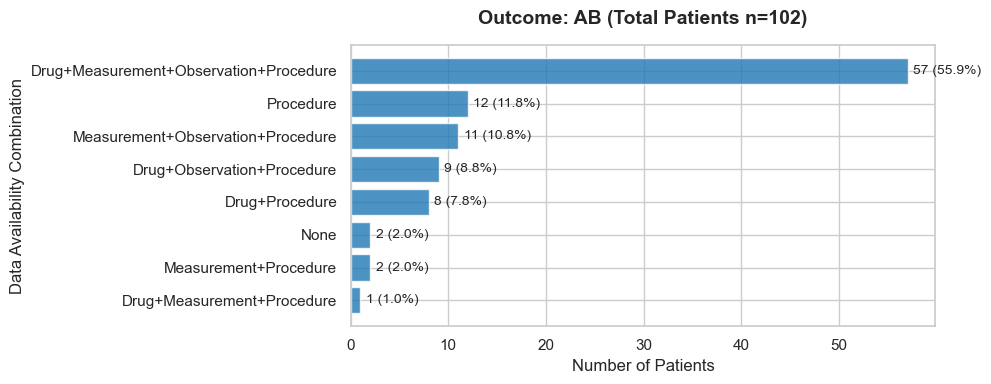

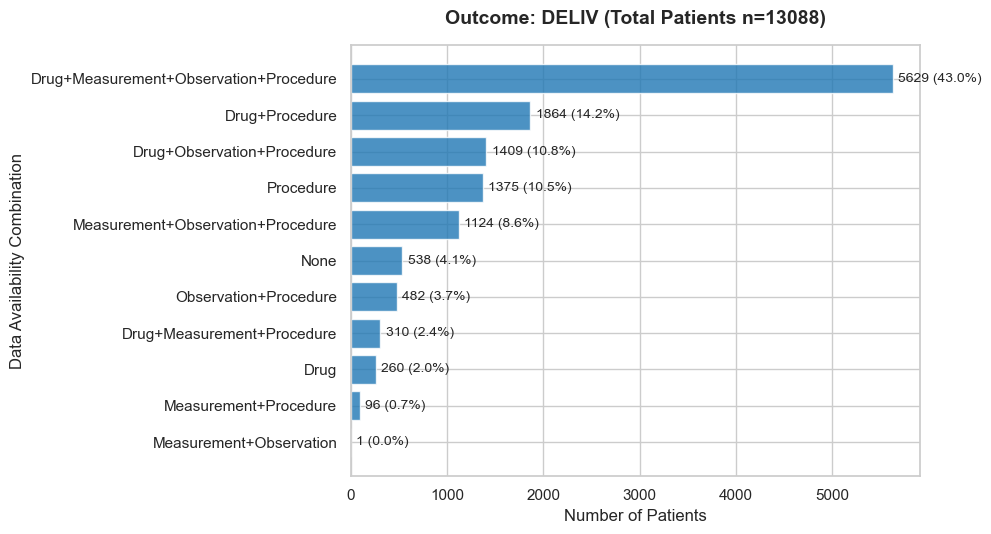

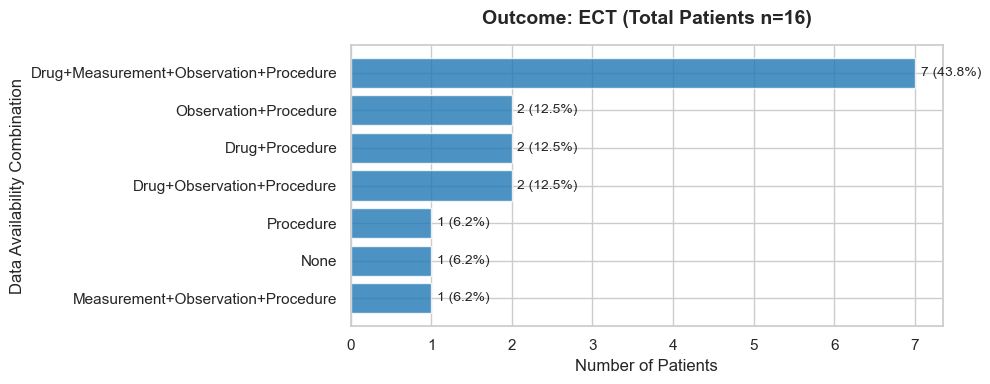

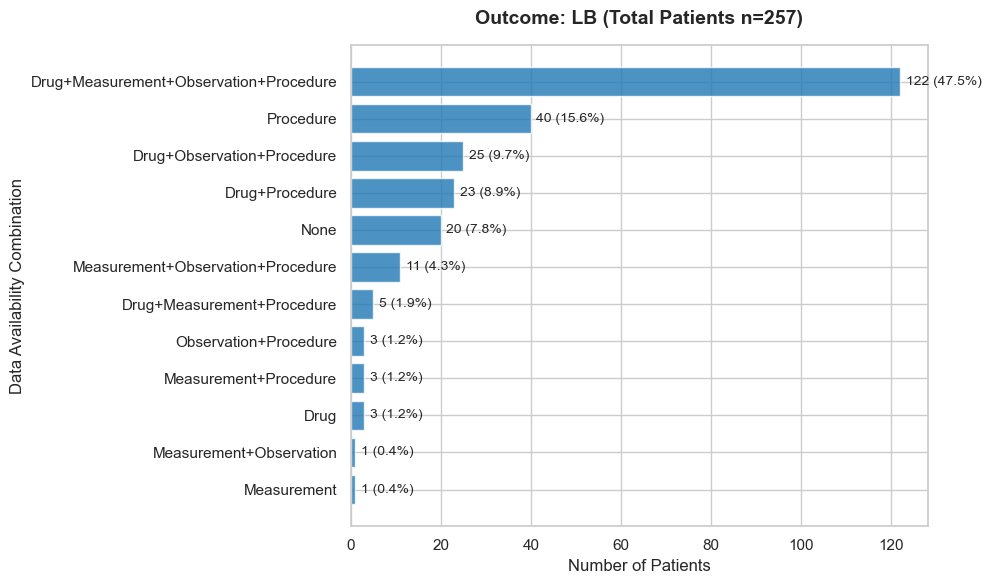

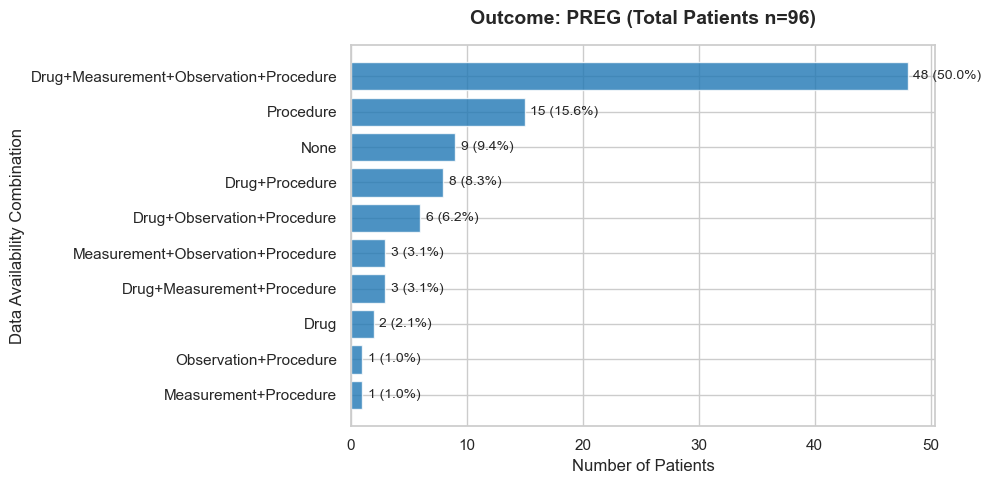

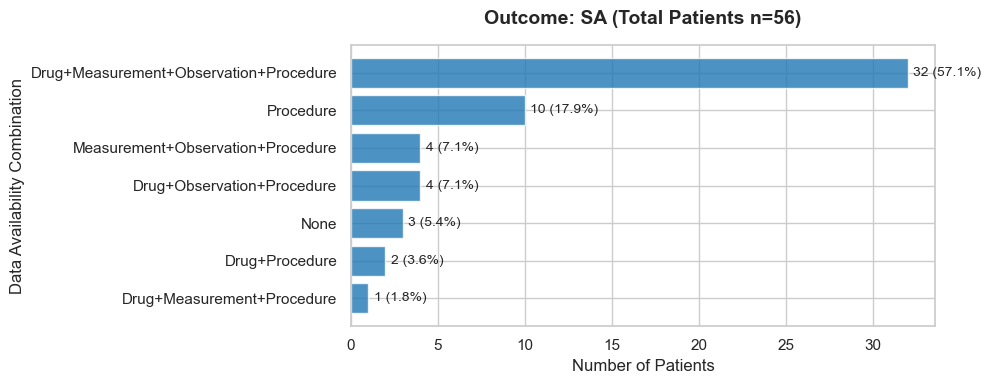

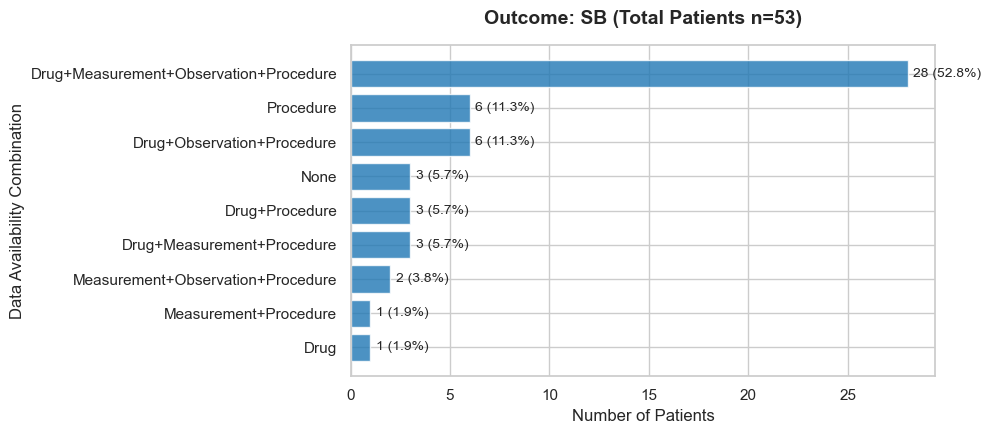

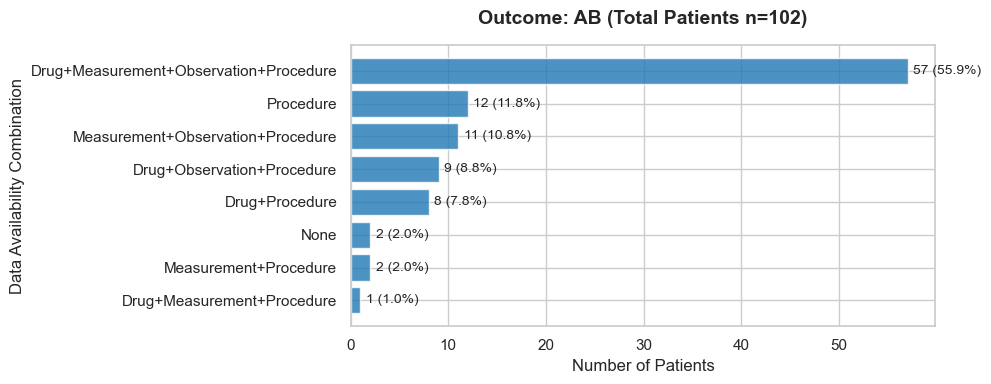

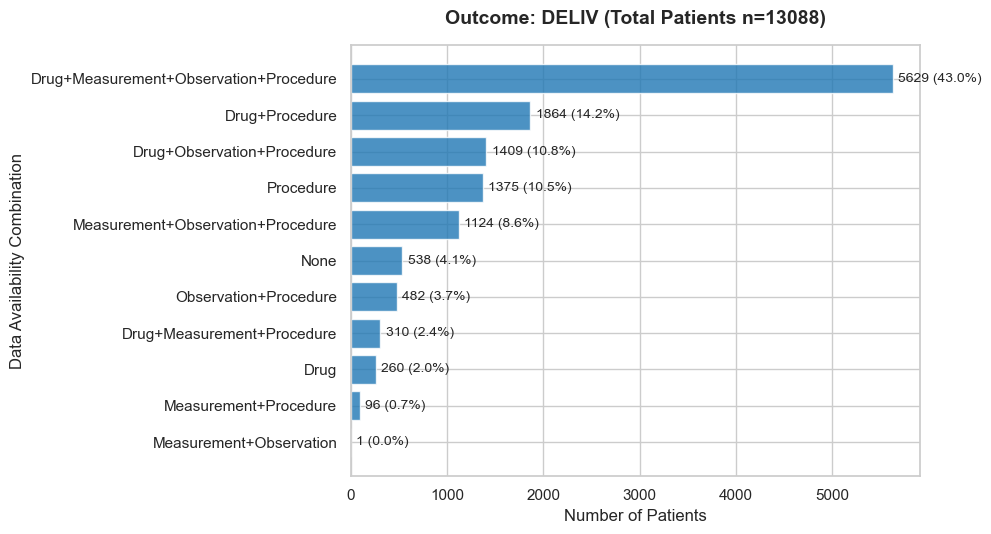

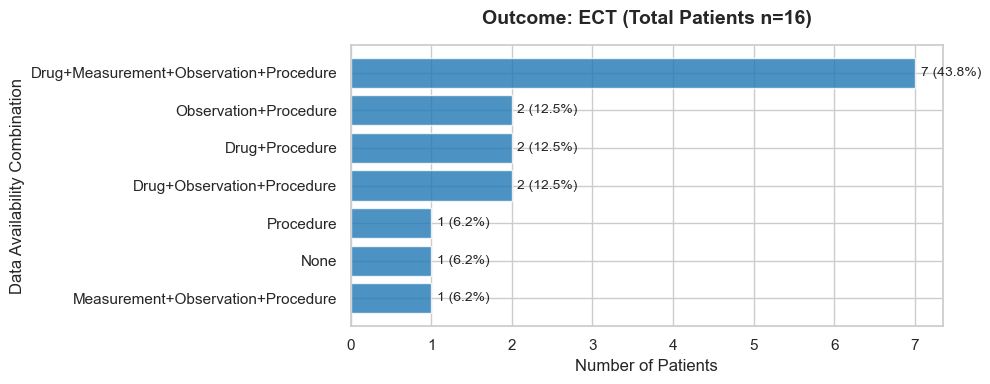

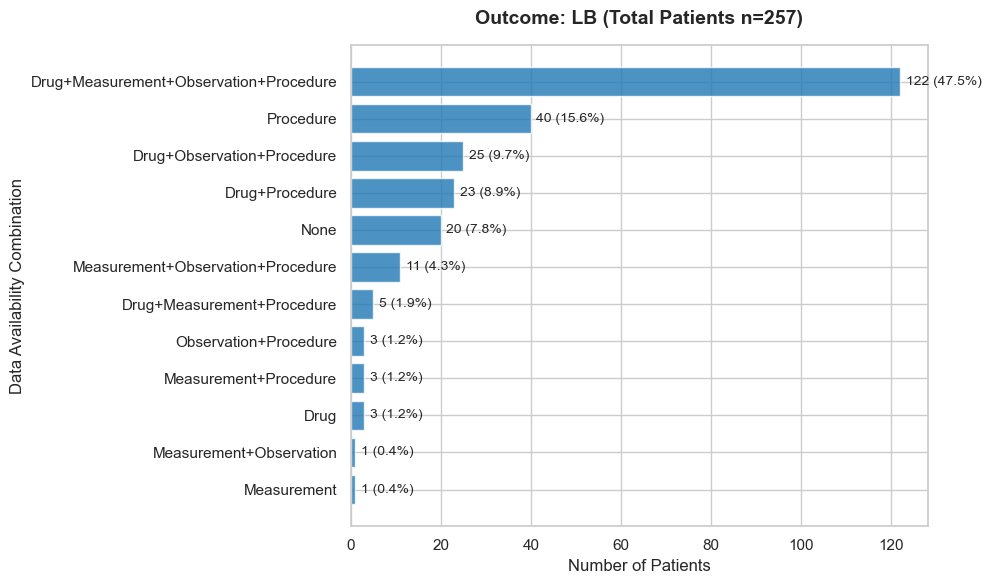

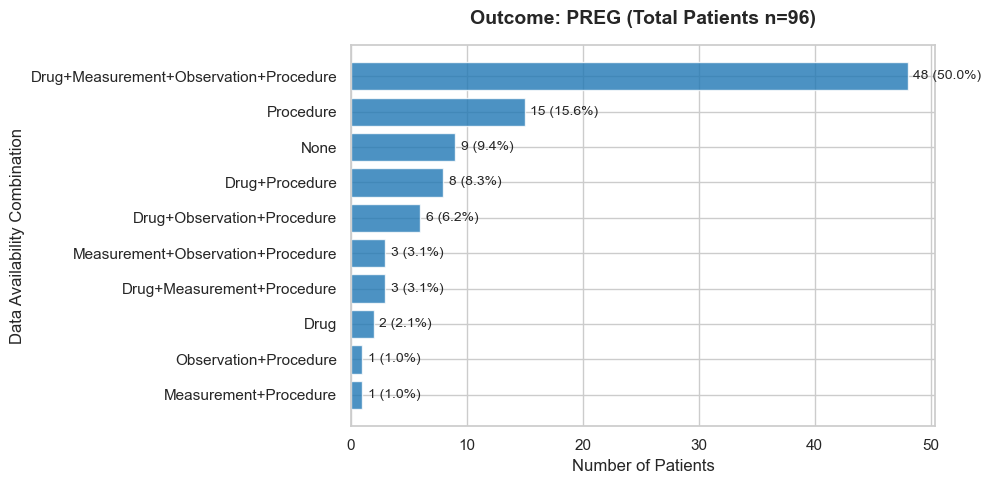

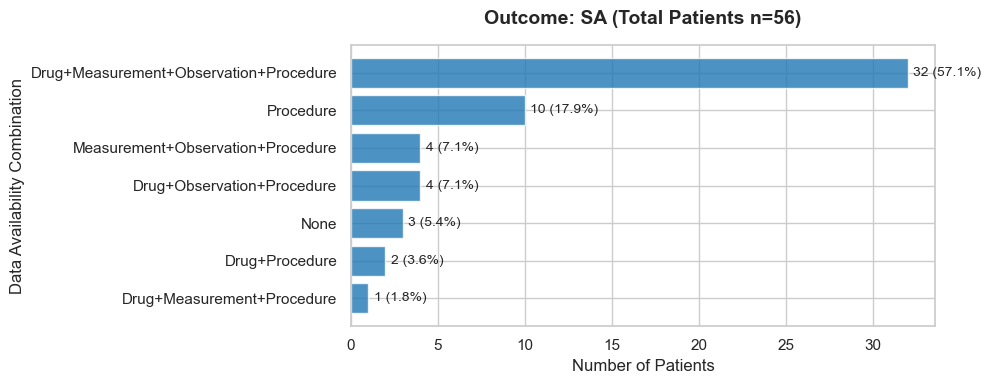

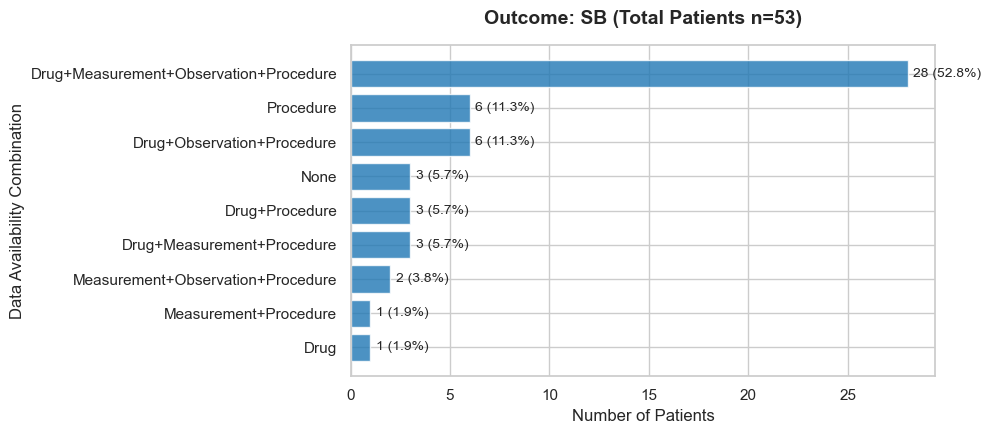

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

threshold = 50
table_names = ['Drug', 'Measurement', 'Observation', 'Procedure']
bool_cols = ['has_drug', 'has_measurement', 'has_observation', 'has_procedure']

# -------------------------
# Build patient-level flags
# -------------------------
person_ids = pregnancy_cohort['person_id'].unique()
table_counts = pd.DataFrame({'person_id': person_ids})

table_counts = (
    table_counts
    .merge(drug_exp.groupby('person_id').size().rename('drug_count'), on='person_id', how='left')
    .merge(measurements.groupby('person_id').size().rename('measurement_count'), on='person_id', how='left')
    .merge(observations.groupby('person_id').size().rename('observation_count'), on='person_id', how='left')
    .merge(procedures.groupby('person_id').size().rename('procedure_count'), on='person_id', how='left')
    .fillna(0)
)

for col in ['drug_count', 'measurement_count', 'observation_count', 'procedure_count']:
    table_counts[col] = table_counts[col].astype(int)

table_counts['has_drug'] = table_counts['drug_count'] >= threshold
table_counts['has_measurement'] = table_counts['measurement_count'] >= threshold
table_counts['has_observation'] = table_counts['observation_count'] >= threshold
table_counts['has_procedure'] = table_counts['procedure_count'] >= threshold

# Unique patient-outcome pairs
outcome_patients = pregnancy_cohort[['person_id', 'final_outcome_category']].drop_duplicates()

# Join flags to patient-outcome rows
combined = outcome_patients.merge(
    table_counts[['person_id'] + bool_cols],
    on='person_id',
    how='left'
).fillna(False)

# Rename columns for plotting
combined = combined.rename(columns={
    'has_drug': 'Drug',
    'has_measurement': 'Measurement',
    'has_observation': 'Observation',
    'has_procedure': 'Procedure'
})
set_cols = ['Drug', 'Measurement', 'Observation', 'Procedure']

# Enforce strict bool
for c in set_cols:
    combined[c] = combined[c].astype(bool)

def combo_label_from_bools(row):
    labels = [name for name in set_cols if row[name]]
    return '+'.join(labels) if labels else 'None'

def plot_outcome_distribution(outcome):
    # Filter for the specific outcome
    subset = combined[combined['final_outcome_category'] == outcome].copy()
    n_patients = len(subset)
    
    if n_patients == 0:
        return

    # Calculate combination counts
    combo_counts = (
        subset.assign(combo=subset.apply(combo_label_from_bools, axis=1))
        .groupby('combo')
        .size()
        .reset_index(name='count')
        .sort_values('count', ascending=True) # Ascending for a clean horizontal layout
    )

    # Plotting
    plt.figure(figsize=(10, max(4, 0.5 * len(combo_counts))))
    
    # Create horizontal bars
    bars = plt.barh(combo_counts['combo'], combo_counts['count'], color='tab:blue', alpha=0.8)
    
    # Label the top/title with the total N
    plt.title(f'Outcome: {outcome} (Total Patients n={n_patients})', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Number of Patients')
    plt.ylabel('Data Availability Combination')

    # Add count labels and percentages to the end of each bar
    for bar in bars:
        width = bar.get_width()
        percentage = (width / n_patients) * 100
        plt.text(width + (max(combo_counts['count']) * 0.01), 
                 bar.get_y() + bar.get_height()/2, 
                 f'{int(width)} ({percentage:.1f}%)', 
                 va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

# Run the simplified loop
for outcome in sorted(combined['final_outcome_category'].dropna().unique()):
    plot_outcome_distribution(outcome)

# Run for each outcome
for outcome in sorted(combined['final_outcome_category'].dropna().unique()):
    plot_outcome_distribution(outcome)